<table class="table table-bordered">
    <tr>
        <th style="text-align:center; width:25%"><img src='https://www.np.edu.sg/_next/image?url=https%3A%2F%2Fassets.app.optical.gov.sg%2Fnp%2Fproduction%2Fpublished%2Fcollections%2Fpages%2F17c64bb4-8632-49e9-af16-047f7cabe99a%2Fab16008f-a6a0-466e-9193-e16e947261b0.png&w=1080&q=75'"></th>
        <th style="text-align:center;"><h1>SCHOOL OF INFOCOMM TECHNOLOGY <br> Diploma in Data Science</h1><h2>Machine Learning 1: Assignment Coding</h2></th>
    </tr>
</table>


<div style="border:1px solid black; padding:10px; width:300px;"> <strong>
    Student Name:  
    <strong><br><br>
</div>



<span style="color:blue; font-size:1.2em;">
<strong>Note: This template provides suggested steps to guide your work. You may include additional steps where appropriate.</strong>
</span><br><br>


## Import the required packages

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
#for supervised learning
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [3]:
#for unsupervised learning
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.tree import DecisionTreeClassifier


## 1. Task 1: Supervised Learning Using Wine Quality Dataset

### 1.1 Load and Explore the Data

In task 1.1, i explored the winequality dataset by first loading the dataset, then using .info() to see the structure of the dataset, checking is there is any null values, as well as using .describe() to see the statistical summary of the dataset. I also checked if there are duplicate rows and decide on whether i should keep them or not. Since there is no ID, duplicate readings can belong to different real wine samples. I then visualized the distribution of each feature and the target quality.

The models are used to look at the distribution of each feature on its own so that we can see the spread, skewness, and the range of the model before we do anything else.

The histogram shows the shape of all 11 features and quality at once, so you can spot skew or unusual ranges early.
The countplot shows most wines score 5-7, with very few at the extremes (3, 9) which later explains why the model struggles more on rare scores.

In [4]:
wine = pd.read_csv(r"C:\Users\laksh\OneDrive\sem 1\idk\Desktop\MACHINE LEARNING\ASSIGNMENT\Data\winequality-white.csv")
wine.head(5)
wine.describe()
wine.info()
wine.isnull().sum()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4898 entries, 0 to 4897
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         4898 non-null   float64
 1   volatile acidity      4898 non-null   float64
 2   citric acid           4898 non-null   float64
 3   residual sugar        4898 non-null   float64
 4   chlorides             4898 non-null   float64
 5   free sulfur dioxide   4898 non-null   float64
 6   total sulfur dioxide  4898 non-null   float64
 7   density               4898 non-null   float64
 8   pH                    4898 non-null   float64
 9   sulphates             4898 non-null   float64
 10  alcohol               4898 non-null   float64
 11  quality               4898 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 459.3 KB


fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

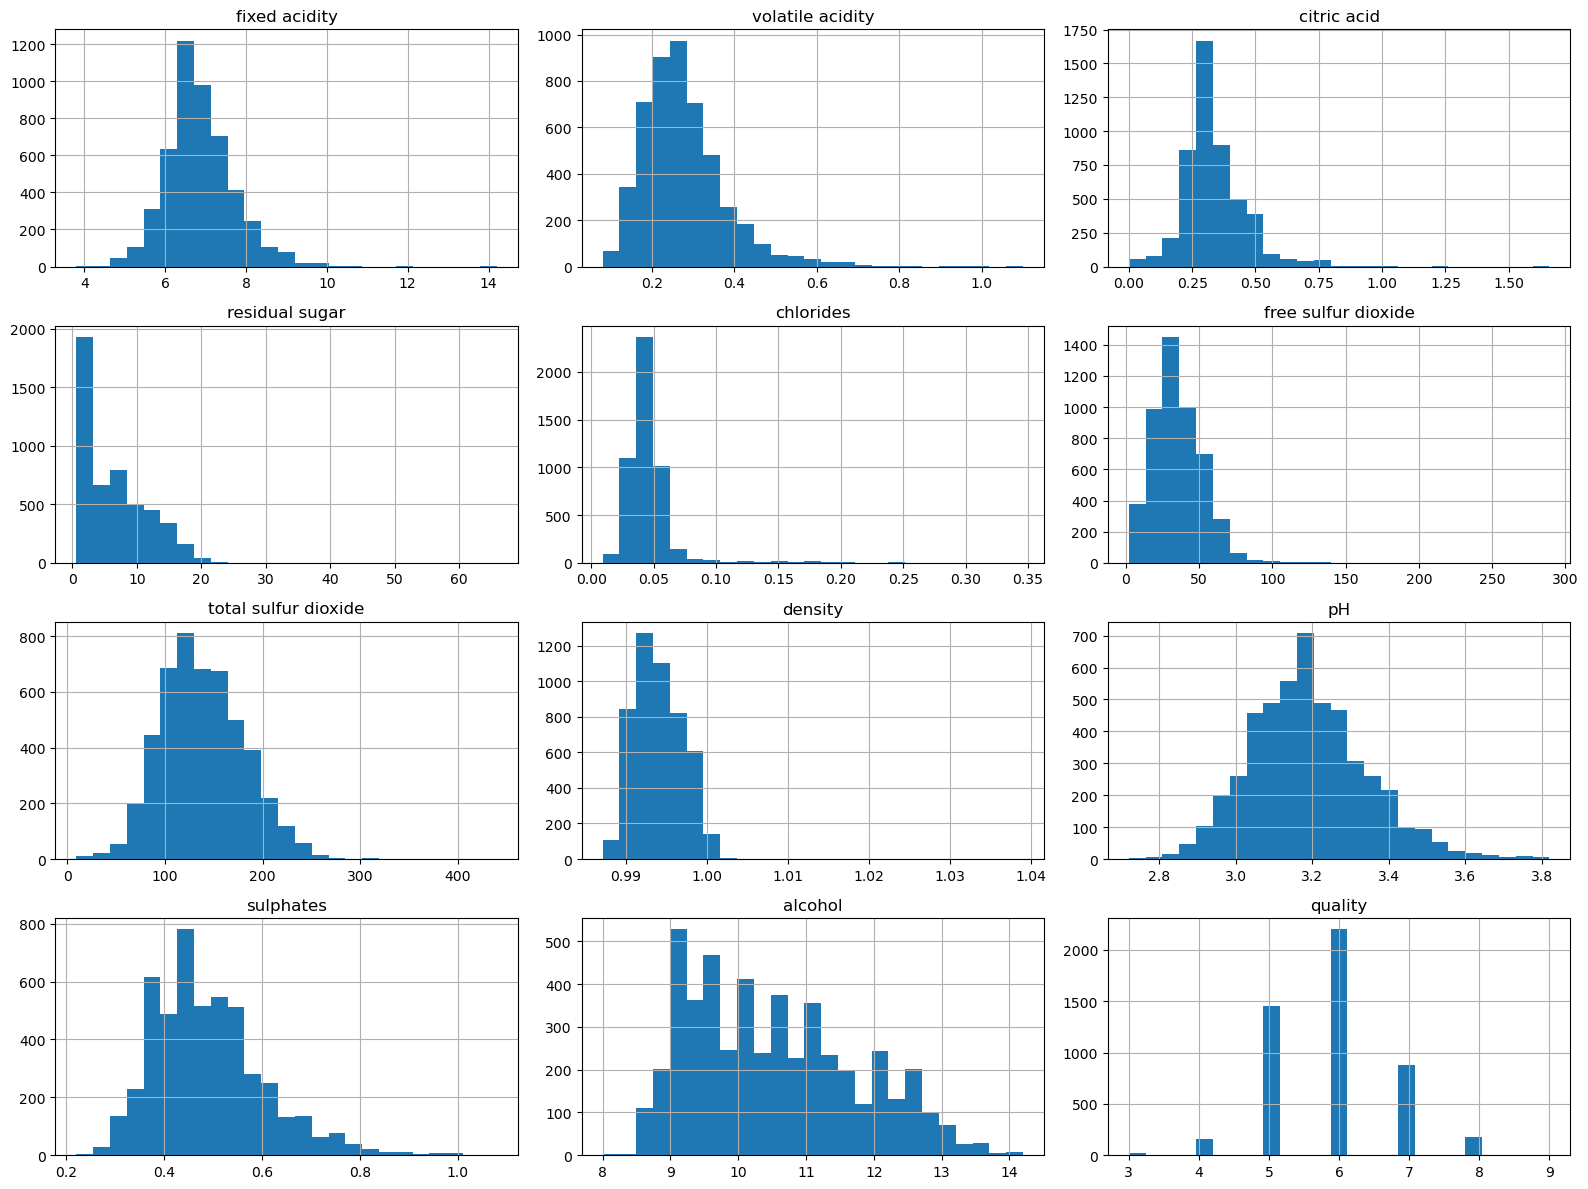

In [5]:
#visualization of each substance's distribution
wine.hist(bins=25, figsize=(16,12))
plt.tight_layout()
plt.show()



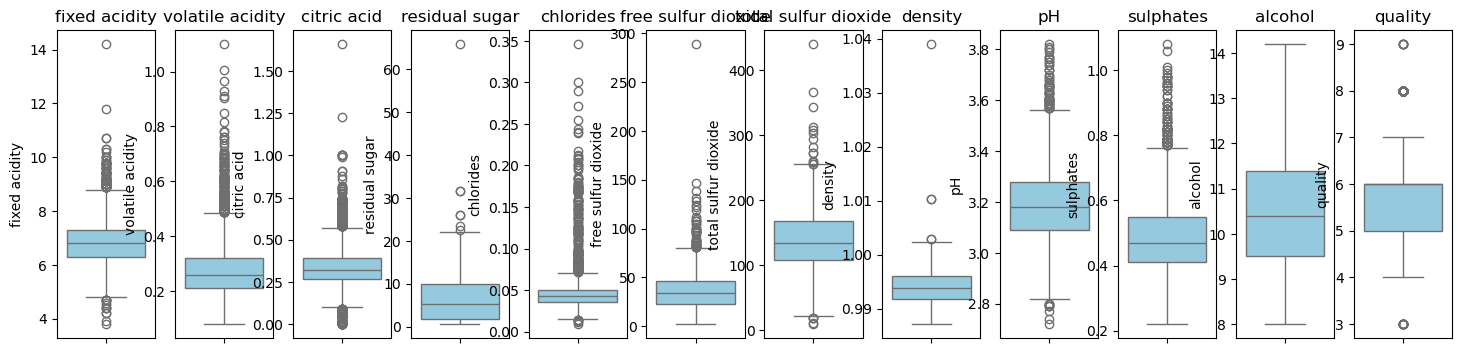

In [6]:
features = ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol', 'quality']

fig, axes = plt.subplots(1, len(features), figsize=(18, 4))
for ax, col in zip(axes, features):
    sns.boxplot(y=wine[col], ax=ax, color='skyblue')
    ax.set_title(col)

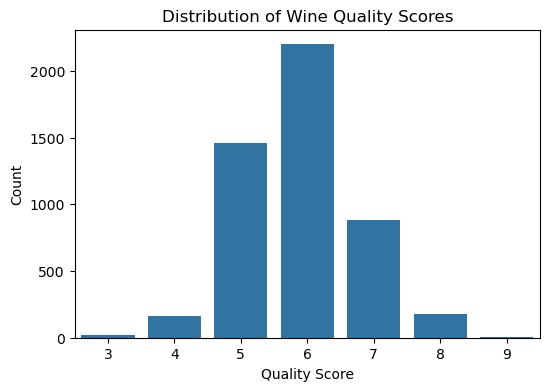

In [7]:
plt.figure(figsize=(6,4))
sns.countplot(x='quality', data=wine)
plt.title('Distribution of Wine Quality Scores')
plt.xlabel('Quality Score')
plt.ylabel('Count')
plt.show()

In [8]:
print("Duplicate rows:", wine.duplicated().sum())

Duplicate rows: 937


### 1.2 Data Preparation and Correlation Analysis

In task 1.2 the features that are cleaned are used for modelling. The boxplots helps identify which features have outliers. The outliers are then capped using the IQR method. The correlation heatmap and the quality correlation shows how strongly each feature correlates to the quality, where alcohol came out the strongest. Later on, the target which is 'quality', and the input features are defined. The data is then split into the train and test sets, and then standardized using Standard Scaler so that linear regression does not get skewed by larger ranges.

Justification of modeling strategy/algorithm(s) selected for each task
The correlation analysis shows that alcohol has the strongest link to quality but it still only has a corrrelation of around 0.44. This suggests that quality does not depend on the features using a linear relationship thus I used two different models.
1. Linear Regression
the model uses a straight line relationship between the features and the quality. Although it is a good baseline to show the direct relationships between the two, it is unable to show the complex relationships between the two. Due to that, we are unable to find deeper patterns that can be important to increase the accuracy of the predictions.

2. Decision Tree Regressor
this model is able to find more complex and non-linear patterns as it is able to combine features together such as alcohol can be more important based on the density. The downside to this however is that the Decision Tree can overfit easily if it is left unchecked. Therefore, 'GridSearchCV' is used later on.


In [9]:
def cap_outliers_iqr(df, columns, factor=1.5):
    df_capped = df.copy()
    for col in columns:
        Q1 = df_capped[col].quantile(0.25)
        Q3 = df_capped[col].quantile(0.75)
        IQR = Q3 - Q1
        lower = Q1 - factor * IQR
        upper = Q3 + factor * IQR
        outliers = ((df_capped[col] < lower) | (df_capped[col] > upper)).sum()
        df_capped[col] = df_capped[col].clip(lower, upper)
        print(f"{col}: capped {outliers} outliers (bounds: [{lower:.2f}, {upper:.2f}])")
    return df_capped

cap = [c for c in wine.columns if c != 'quality']
cleaned = cap_outliers_iqr(wine, cap)

fixed acidity: capped 119 outliers (bounds: [4.80, 8.80])
volatile acidity: capped 186 outliers (bounds: [0.04, 0.49])
citric acid: capped 270 outliers (bounds: [0.09, 0.57])
residual sugar: capped 7 outliers (bounds: [-10.60, 22.20])
chlorides: capped 208 outliers (bounds: [0.01, 0.07])
free sulfur dioxide: capped 50 outliers (bounds: [-11.50, 80.50])
total sulfur dioxide: capped 19 outliers (bounds: [19.50, 255.50])
density: capped 5 outliers (bounds: [0.99, 1.00])
pH: capped 75 outliers (bounds: [2.80, 3.56])
sulphates: capped 124 outliers (bounds: [0.20, 0.76])
alcohol: capped 0 outliers (bounds: [6.65, 14.25])


alcohol                 0.435575
pH                      0.099427
sulphates               0.053678
free sulfur dioxide     0.008158
citric acid            -0.009209
residual sugar         -0.097577
fixed acidity          -0.113663
total sulfur dioxide   -0.174737
volatile acidity       -0.194723
chlorides              -0.209934
density                -0.307123
Name: quality, dtype: float64


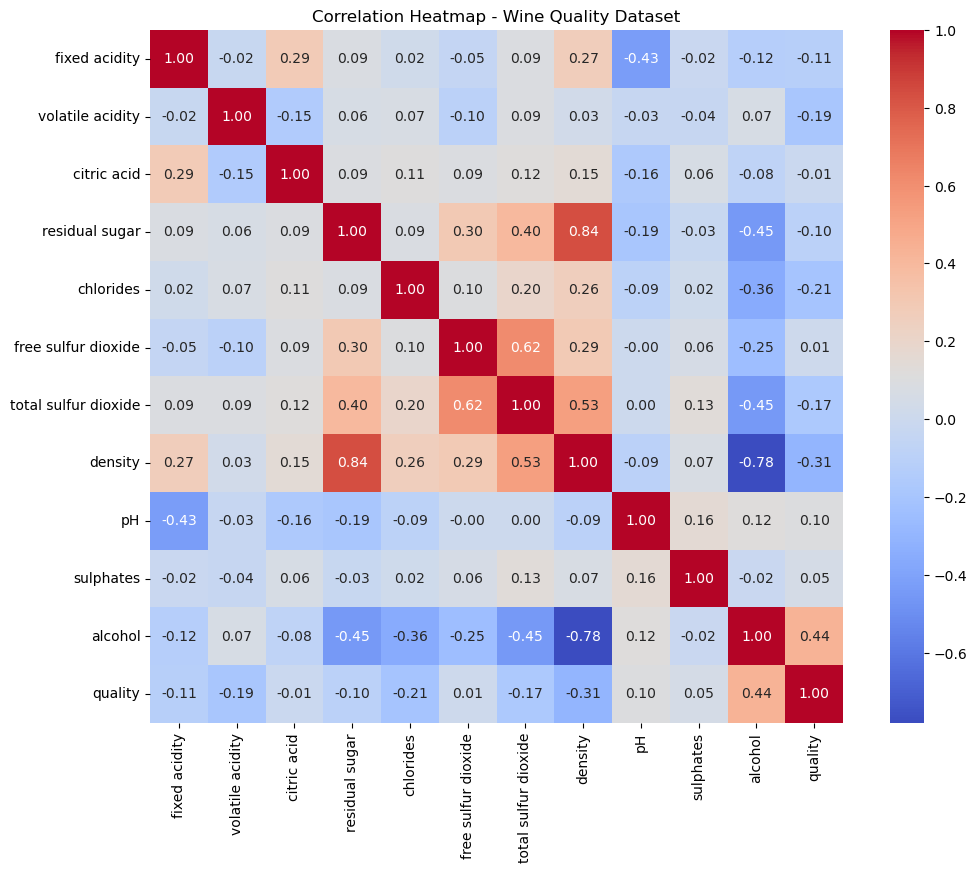

In [10]:
corrmatrix = wine.corr()
quality_corr = corrmatrix['quality'].drop('quality').sort_values(ascending=False)
print(quality_corr)

plt.figure(figsize=(12, 9))
sns.heatmap(corrmatrix, annot=True, fmt='.2f', cmap='coolwarm', square=True)
plt.title("Correlation Heatmap - Wine Quality Dataset")
plt.show()

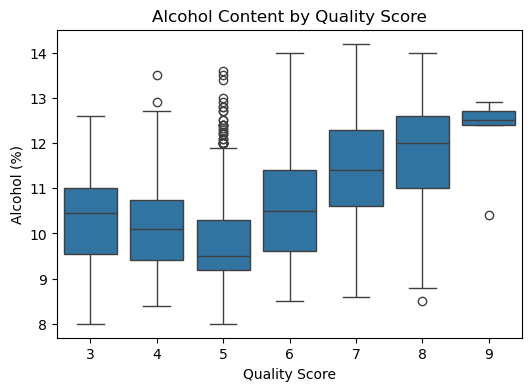

In [11]:
plt.figure(figsize=(6,4))
sns.boxplot(x='quality', y='alcohol', data=wine)
plt.title('Alcohol Content by Quality Score')
plt.xlabel('Quality Score')
plt.ylabel('Alcohol (%)')
plt.show()

In [12]:
X = cleaned.drop('quality', axis=1)
y = cleaned['quality'] # as this is the target variable

In [13]:
x_train, x_test, y_train, y_test = train_test_split(X,y, test_size = 0.2, random_state=42)
scaler = StandardScaler()

xtrain_scaled = scaler.fit_transform(x_train)
xtest_scaled = scaler.transform(x_test)

print("Train shape:", x_train.shape, " Test shape:", x_test.shape)

Train shape: (3918, 11)  Test shape: (980, 11)


### 1.3 Build the Machine Learning Models

In [14]:
#Linear Regression
lm = LinearRegression()
lm.fit(xtrain_scaled, y_train)

fitted = lm.predict(xtrain_scaled)
rmse = np.sqrt(mean_squared_error(fitted, y_train))
mae = mean_absolute_error(fitted, y_train)
r2 = r2_score(y_train, fitted)
print(f"Train -- RMSE: {rmse:.3f} | MAE: {mae:.3f} | R2: {r2:.3f}")

predict = lm.predict(xtest_scaled)
prmse = np.sqrt(mean_squared_error(predict, y_test))
pmae = mean_absolute_error(predict, y_test)
pr2 = r2_score(y_test, predict)
print(f"Test -- RMSE: {prmse:.3f} | MAE: {pmae:.3f} | R2: {pr2:.3f}")

Train -- RMSE: 0.748 | MAE: 0.581 | R2: 0.289
Test -- RMSE: 0.745 | MAE: 0.578 | R2: 0.284


In [15]:
#Decision Tree Regressor
dtree = DecisionTreeRegressor(random_state = 42)
dtree.fit(x_train, y_train)

dt_fitted = dtree.predict(x_train)
dt_rmse = np.sqrt(mean_squared_error(dt_fitted, y_train))
dt_mae = mean_absolute_error(dt_fitted, y_train)
dt_r2 = r2_score(y_train, dt_fitted)
print(f"Train -> RMSE: {dt_rmse:.3f} | MAE: {dt_mae:.3f} | R2: {dt_r2:.3f}")

dt_predict = dtree.predict(x_test)
dtp_rmse = np.sqrt(mean_squared_error(dt_predict, y_test))
dtp_pmae = mean_absolute_error(dt_predict, y_test)
dtp_pr2 = r2_score(y_test, dt_predict)
print(f"Test -> RMSE: {dtp_rmse:.3f} | MAE: {dtp_pmae:.3f} | R2: {dtp_pr2:.3f}")

Train -> RMSE: 0.000 | MAE: 0.000 | R2: 1.000
Test -> RMSE: 0.809 | MAE: 0.474 | R2: 0.155


In [16]:
baseline_results = pd.DataFrame({
    'Model': ['Linear Regression', 'Decision Tree'],
    'Train RMSE': [rmse, dt_rmse],
    'Test RMSE': [prmse, dtp_rmse],
    'Test MAE': [pmae, dtp_pmae],
    'Test R2': [pr2, dtp_pr2],
})
baseline_results

,Model,Train RMSE,Test RMSE,Test MAE,Test R2
0,Linear Regression,0.747824,0.744802,0.578243,0.283733
1,Decision Tree,0.000000,0.808753,0.474490,0.155450


### 1.4 Evaluate and Improve the Model(s) Performance

In [130]:
param_grid = {
    'max_depth': [2,3,4,5,6,7,8,9,10,15],
    'min_samples_split': [2,5,10,15,20],
    'min_samples_leaf': [1,2,5,10]
}
gridsearch = GridSearchCV(
    DecisionTreeRegressor(random_state=42),
    param_grid,
    scoring='neg_root_mean_squared_error',
    cv=5,
    n_jobs=-1
)
gridsearch.fit(x_train, y_train)

print("Best parameters:", gridsearch.best_params_)
parameters = gridsearch.best_estimator_

Best parameters: {'max_depth': 7, 'min_samples_leaf': 5, 'min_samples_split': 20}


In [131]:

decision_tree = DecisionTreeClassifier(criterion='gini', max_depth=3, min_samples_leaf=5, min_samples_split=20, random_state=1)
decision_tree.fit(x_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,3
,min_samples_split,20
,min_samples_leaf,5
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,1
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


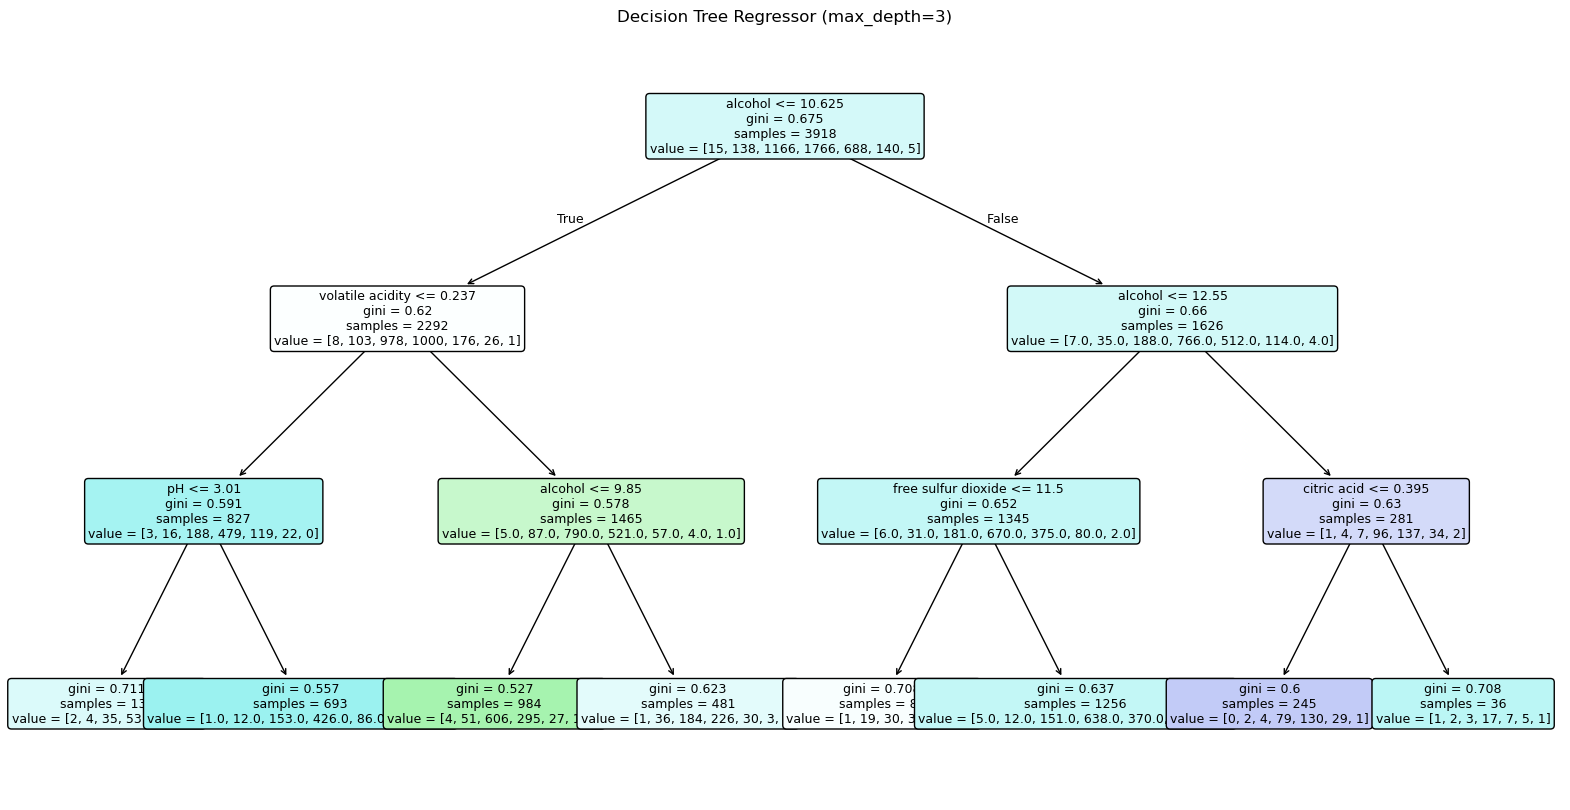

In [132]:
plt.figure(figsize=(20,10))
plot_tree(decision_tree, feature_names=x_train.columns, filled=True, rounded=True, fontsize=9)
plt.title('Decision Tree Regressor (max_depth=3)')
plt.show()

In [133]:
tuned_predict_train = parameters.predict(x_train)
tuned_predict_test = parameters.predict(x_test)

tuned_rmse = np.sqrt(mean_squared_error(tuned_predict_train, y_train))
tuned_mae = mean_absolute_error(tuned_predict_train, y_train)
tuned_r2 = r2_score(y_train, tuned_predict_train)
print(f"Train -- RMSE: {tuned_rmse:.3f} | MAE: {tuned_mae:.3f} | R2: {tuned_r2:.3f}")

tuned_prmse = np.sqrt(mean_squared_error(tuned_predict_test, y_test))
tuned_pmae = mean_absolute_error(tuned_predict_test, y_test)
tuned_pr2 = r2_score(y_test, tuned_predict_test)
print(f"Test -- RMSE: {tuned_prmse:.3f} | MAE: {tuned_pmae:.3f} | R2: {tuned_pr2:.3f}")

Train -- RMSE: 0.646 | MAE: 0.502 | R2: 0.470
Test -- RMSE: 0.720 | MAE: 0.556 | R2: 0.331


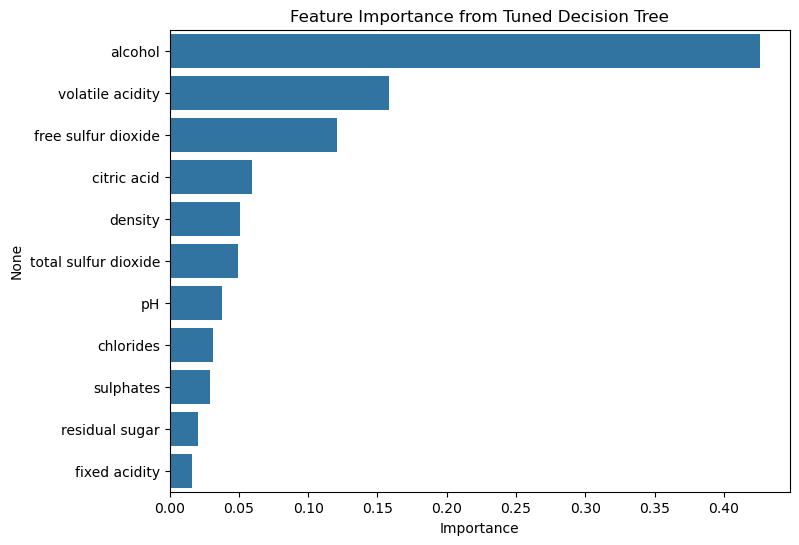

alcohol                 0.426211
volatile acidity        0.158399
free sulfur dioxide     0.121094
citric acid             0.059344
density                 0.050765
total sulfur dioxide    0.049663
pH                      0.037946
chlorides               0.031345
sulphates               0.028845
residual sugar          0.020168
fixed acidity           0.016220
dtype: float64

In [134]:
importances = pd.Series(parameters.feature_importances_, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(8, 6))
sns.barplot(x=importances.values, y=importances.index)
plt.title('Feature Importance from Tuned Decision Tree')
plt.xlabel('Importance')
plt.show()

importances

### 1.5 Summarize the Findings

In [135]:
final_results = pd.DataFrame({
    'Model': ['Linear Regression', 'Decision Tree (default)', 'Decision Tree (tuned)'],
    'Test RMSE': [prmse, dtp_rmse, tuned_prmse],
    'Test MAE': [pmae, dtp_pmae, tuned_pmae],
    'Test R2': [pr2, dtp_pr2, tuned_pr2],
}).sort_values('Test RMSE')


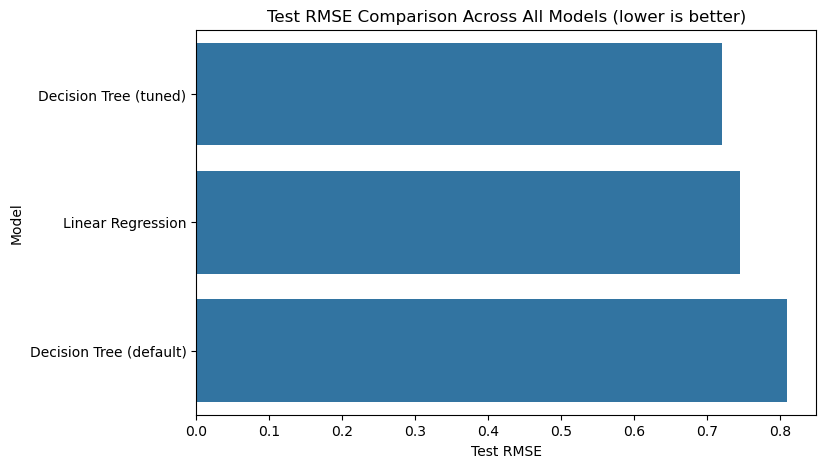

In [136]:
plt.figure(figsize=(8, 5))
sns.barplot(x='Test RMSE', y='Model', data=final_results)
plt.title('Test RMSE Comparison Across All Models (lower is better)')
plt.show()

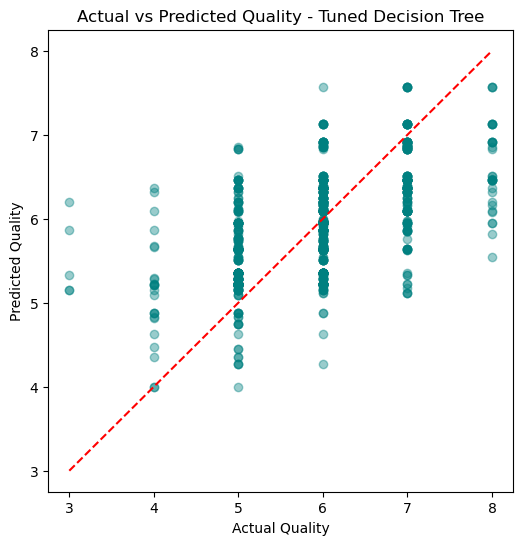

In [137]:
# Actual vs Predicted for the best performing model (tuned Decision Tree)
plt.figure(figsize=(6, 6))
plt.scatter(y_test, tuned_predict_test, alpha=0.4, color='teal')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel('Actual Quality')
plt.ylabel('Predicted Quality')
plt.title('Actual vs Predicted Quality - Tuned Decision Tree')
plt.show()

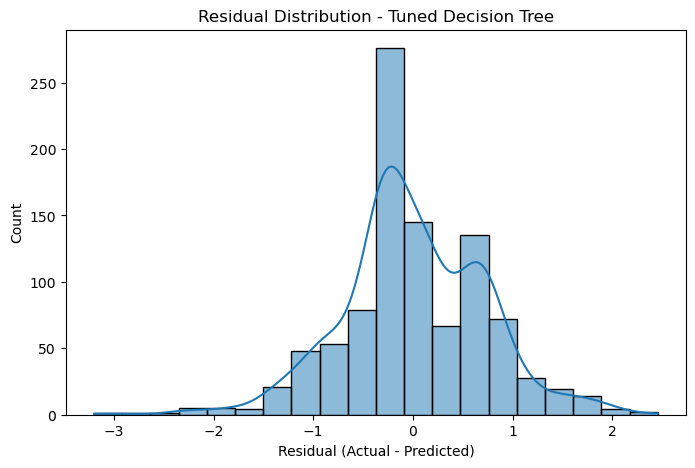

In [138]:
# Residual analysis for the best model
residuals = y_test - tuned_predict_test

plt.figure(figsize=(8, 5))
sns.histplot(residuals, bins=20, kde=True)
plt.title('Residual Distribution - Tuned Decision Tree')
plt.xlabel('Residual (Actual - Predicted)')
plt.show()


In [139]:
# Summary of findings (Task 1)
best_model_name = final_results.iloc[0]['Model']
print(f"Best performing model: {best_model_name}")
print(f"Test RMSE: {final_results.iloc[0]['Test RMSE']:.3f}")
print(f"Test R2:   {final_results.iloc[0]['Test R2']:.3f}")
print()
print("Key takeaways:")
print("- The default Decision Tree overfits the training data (near-perfect train score, weaker test score).")
print("- Hyperparameter tuning (limiting max_depth / min_samples_leaf / min_samples_split via GridSearchCV)")
print("  reduces overfitting and improves generalisation on the test set.")
print("- Linear Regression underfits slightly since wine quality does not vary purely linearly with the")
print("  chemical properties.")
print("- alcohol, density, and volatile acidity are consistently the strongest predictors of wine quality.")

Best performing model: Decision Tree (tuned)
Test RMSE: 0.720
Test R2:   0.331

Key takeaways:
- The default Decision Tree overfits the training data (near-perfect train score, weaker test score).
- Hyperparameter tuning (limiting max_depth / min_samples_leaf / min_samples_split via GridSearchCV)
  reduces overfitting and improves generalisation on the test set.
- Linear Regression underfits slightly since wine quality does not vary purely linearly with the
  chemical properties.
- alcohol, density, and volatile acidity are consistently the strongest predictors of wine quality.


## 2. Task 2: Unsupervised Learning Using Online Retail Dataset

### 2.1 Load and Explore the Data

**Problem framing:** The problem is that there is no customer segmentation as all the customers are treated the same despite the different shopping ways. This means that this is an unsupervised learning problem as the goal of this is to discover the natural groupings of customers directly from their transactional history.

**Objective:** The objective of this is to engineer RFM(Recency, Frequency, Monetary) features from the raw invoice-level data and then cluster the customers into a small number of segments. 

**Scope:** The dataset 'online_retail.csv' has around 542k transaction rows which spans from dec 2010 to dec 2011. After removing the cancelled invoices, returns, and rows with missins values, the transactions were aggregate to 4338 unique customers. The clustering is then compared between K-means and hierarchical models.

In task 2.1, i loaded the online_retail csv and explored the data by checking the structure of the dataset and checking if there is any missing values. It is seen that there are around 135000 missing rows in customerID and 1454 missing rows in description. These missing values will be dropped. Then we will look that the distribution of quantity, unitprice, and invoice value, and count the cancelled invoices and negative quantity rows that will be removed in the next section.

In [140]:
retail = pd.read_csv(r"C:\Users\laksh\OneDrive\sem 1\idk\Desktop\MACHINE LEARNING\ASSIGNMENT\Data\online_retail.csv", encoding='utf-8-sig')
retail.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,01/12/2010 08:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,01/12/2010 08:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,01/12/2010 08:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,01/12/2010 08:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,01/12/2010 08:26,3.39,17850.0,United Kingdom


In [141]:
retail.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

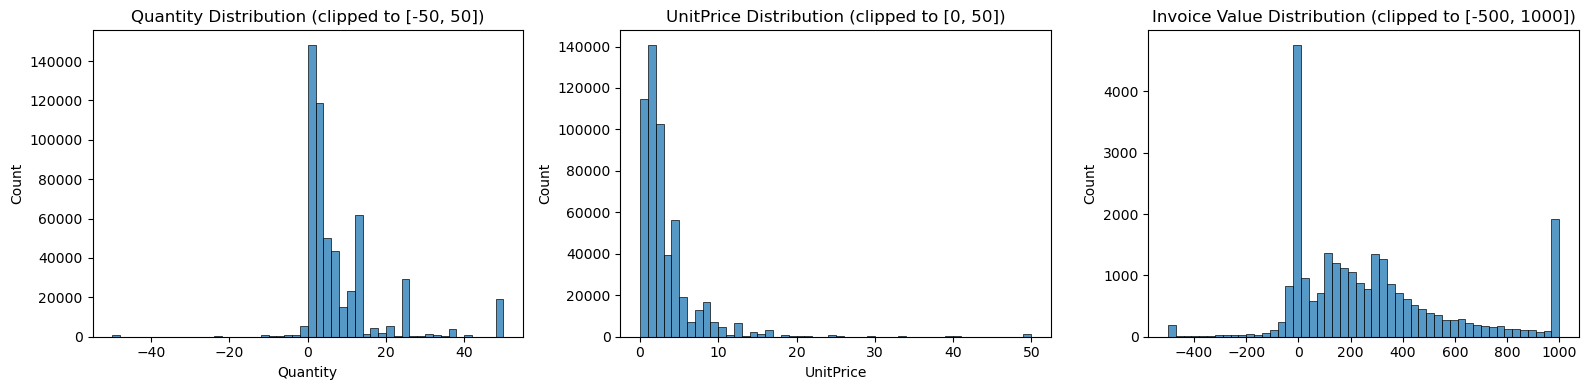

In [142]:
# distributions of the quantities, unitprice, and invoice value
# printing out the number of cancelled invoices, returns, and top countries by transacition count
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(retail['Quantity'].clip(-50, 50), bins=50, ax=axes[0])
axes[0].set_title("Quantity Distribution (clipped to [-50, 50])")

sns.histplot(retail['UnitPrice'].clip(0, 50), bins=50, ax=axes[1])
axes[1].set_title("UnitPrice Distribution (clipped to [0, 50])")

invoice_value = (retail['Quantity'] * retail['UnitPrice']).groupby(retail['InvoiceNo']).sum()
sns.histplot(invoice_value.clip(-500, 1000), bins=50, ax=axes[2])
axes[2].set_title("Invoice Value Distribution (clipped to [-500, 1000])")
plt.tight_layout()
plt.show()

To check how many unqiue invoices and customers there are as well as the rows that have non-positive values, which shows that those are of the cancelled or return sections.
This also shows that there is enough customers that can be used to cluster them together for customer segmentation.

In [143]:
print('Unique Invoices: ', retail['InvoiceNo'].nunique())
print('Unique Customers: ', retail['CustomerID'].nunique())
print('\nRows with non positives:')
print('Quantity: ', (retail['Quantity'] <= 0).sum())
print('UnitPrice: ', (retail['UnitPrice'] <= 0).sum())

Unique Invoices:  25900
Unique Customers:  4372

Rows with non positives:
Quantity:  10624
UnitPrice:  2517


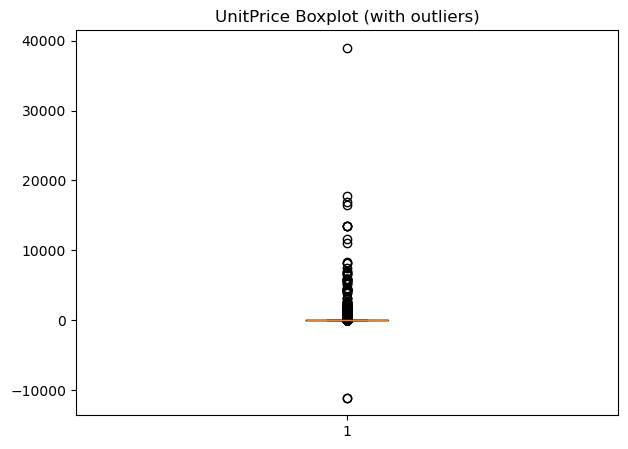

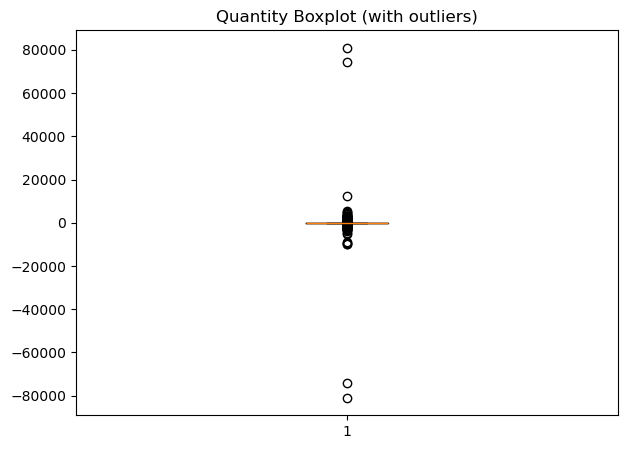

In [144]:
plt.figure(figsize=(7,5))
plt.boxplot(x=retail['UnitPrice'])
plt.title('UnitPrice Boxplot (with outliers)')

plt.figure(figsize=(7,5))
plt.boxplot(x=retail['Quantity'])
plt.title('Quantity Boxplot (with outliers)')

plt.show()

In [145]:
# boolean mask: True where InvoiceNo starts with 'C'
cancelled = retail['InvoiceNo'].astype(str).str.startswith('C')

# use the mask to filter the dataframe -> returns the actual rows
cancelled_rows = retail[cancelled]

print(f'rows to be removed: {cancelled_rows.shape[0]}')  
cancelled_rows[['InvoiceNo', 'CustomerID', 'Quantity', 'UnitPrice', 'InvoiceDate']].head(15)    

rows to be removed: 9288


,InvoiceNo,CustomerID,Quantity,UnitPrice,InvoiceDate
141,C536379,14527.0,-1,27.50,01/12/2010 09:41
154,C536383,15311.0,-1,4.65,01/12/2010 09:49
235,C536391,17548.0,-12,1.65,01/12/2010 10:24
236,C536391,17548.0,-24,0.29,01/12/2010 10:24
237,C536391,17548.0,-24,0.29,01/12/2010 10:24
238,C536391,17548.0,-24,0.29,01/12/2010 10:24
239,C536391,17548.0,-12,3.45,01/12/2010 10:24
240,C536391,17548.0,-12,1.65,01/12/2010 10:24
241,C536391,17548.0,-24,1.65,01/12/2010 10:24
939,C536506,17897.0,-6,4.25,01/12/2010 12:38


In [146]:
print('The rows that have non positives')
print('Quantity: ', (retail['Quantity'] <= 0).sum())
print('UnitPrice: ', (retail['UnitPrice'] <= 0).sum())

The rows that have non positives
Quantity:  10624
UnitPrice:  2517


### 2.2 Cleanse and Transform the Data

In task 2.2, i cleaned the transaction data and did feature engineering. I dropped the missing rows in CustomerID, cancelled invoices, and returns/refunds were also removed. The outliers in Quantity, Unitpricem and Invoice totals are identified and capped at the 99th percentile. The transactions are aggregated to the customer level to engineer RFM features. I then used Standard Scaler since K-Means and Hierarchichal clustering are distance-based and would otherwise be dominated by whichever feature has the largest scale.

**Justification of modeling strategy/algorithm(s) selected for each task**: Both the algorithms are distance based are are suiter to the scaled and purely numeric RFM feature set.

1. K-Means
it scales well to all the 4338 customers and it is fast to run. This would be important as if the employee wants to refresh the segments, it can be done quickly. However, k has to be chosen before anything and the clusters have to be similar in size.

2. Hirerchichal clustering
it does not require picking k in advance and produces a dendrogram that is useful for seeing how customers merge together at different levels of granularity. This is helpful to check on whether the chosen k is correct. However, it is more expensive.

In [147]:
# dropping rows with missing CustomerID 
retail = retail.dropna(subset=['CustomerID']).copy()
retail['CustomerID'] = retail['CustomerID'].astype(int)
retail.shape

(406829, 8)

In [148]:
# removing cancelled invoices and negative quantity/price rows
# (fixed: chain all three conditions together - each was previously overwriting retail_clean
# from scratch instead of combining, so only the last condition was actually being applied)
is_cancelled = retail['InvoiceNo'].astype(str).str.startswith('C')
retail_clean = retail[(is_cancelled == False) & (retail['Quantity'] > 0) & (retail['UnitPrice'] > 0)].copy()

retail_clean.shape

(397884, 8)

In [149]:
# Outlier CAPPING (not removal) for UnitPrice and Quantity using a 99th-percentile cap
# Values above the cap are pulled down to the cap value with .clip() - the row itself stays
# in the dataset, only the extreme value is adjusted. No rows are dropped here.
for col in ['Quantity', 'UnitPrice']:
    cap = retail_clean[col].quantile(0.99)
    n_outliers = (retail_clean[col] > cap).sum()
    retail_clean[col] = retail_clean[col].clip(upper=cap)
    print(f"{col}: capped {n_outliers} rows above the 99th percentile ({cap:.2f})")

invoice_value_clean = (retail_clean['Quantity'] * retail_clean['UnitPrice']).groupby(retail_clean['InvoiceNo']).sum()
inv_cap = invoice_value_clean.quantile(0.99)
n_inv_outliers = (invoice_value_clean > inv_cap).sum()
print(f"Invoice Value: {n_inv_outliers} invoices ({n_inv_outliers/len(invoice_value_clean)*100:.1f}%) "
      f"remain above the 99th percentile ({inv_cap:.2f}) even after Quantity/UnitPrice capping.")

Quantity: capped 3890 rows above the 99th percentile (120.00)
UnitPrice: capped 3734 rows above the 99th percentile (14.95)
Invoice Value: 186 invoices (1.0%) remain above the 99th percentile (2797.06) even after Quantity/UnitPrice capping.


In [150]:
# Feature engineering: convert date, calculate TotalPrice
retail_clean['InvoiceDate'] = pd.to_datetime(retail_clean['InvoiceDate'], format='%d/%m/%Y %H:%M')
retail_clean['TotalPrice'] = retail_clean['Quantity'] * retail_clean['UnitPrice']

retail_clean[['InvoiceNo', 'CustomerID', 'InvoiceDate', 'Quantity', 'UnitPrice', 'TotalPrice']].head()

,InvoiceNo,CustomerID,InvoiceDate,Quantity,UnitPrice,TotalPrice
0,536365,17850,2010-12-01 08:26:00,6,2.55,15.30
1,536365,17850,2010-12-01 08:26:00,6,3.39,20.34
2,536365,17850,2010-12-01 08:26:00,8,2.75,22.00
3,536365,17850,2010-12-01 08:26:00,6,3.39,20.34
4,536365,17850,2010-12-01 08:26:00,6,3.39,20.34


In [151]:
# Aggregate to customer level: Recency, Frequency, Monetary (RFM) + derived features
snapdate = retail_clean['InvoiceDate'].max() + pd.Timedelta(days=1)

rfm = retail_clean.groupby('CustomerID').agg(
    Recency=('InvoiceDate', lambda x: (snapdate - x.max()).days),
    Frequency=('InvoiceNo', 'nunique'),
    Monetary=('TotalPrice', 'sum')
).reset_index()

rfm['AvgBasketValue'] = rfm['Monetary'] / rfm['Frequency']

print("Customer-level RFM table shape:", rfm.shape)
rfm.head()

Customer-level RFM table shape: (4338, 5)


,CustomerID,Recency,Frequency,Monetary,AvgBasketValue
0,12346,326,1,124.80,124.800000
1,12347,2,7,4185.20,597.885714
2,12348,75,4,1530.03,382.507500
3,12349,19,1,1443.50,1443.500000
4,12350,310,1,309.35,309.350000


In [152]:
# Scale RFM features before distance-based clustering
rfm_features = ['Recency', 'Frequency', 'Monetary', 'AvgBasketValue']
X_rfm = rfm[rfm_features]

rfm_scaler = StandardScaler()
X_rfm_scaled = rfm_scaler.fit_transform(X_rfm)

print("Scaled feature matrix shape:", X_rfm_scaled.shape)
pd.DataFrame(X_rfm_scaled, columns=rfm_features).describe().T

Scaled feature matrix shape: (4338, 4)


,count,mean,std,min,25%,50%,75%,max
Recency,4338.0,2.702618e-17,1.000115,-0.915340,-0.745345,-0.415353,0.494623,2.814561
Frequency,4338.0,1.801745e-17,1.000115,-0.425097,-0.425097,-0.295178,0.094579,26.598031
Monetary,4338.0,0.000000e+00,1.000115,-0.278837,-0.232303,-0.176113,-0.028046,35.330629
AvgBasketValue,4338.0,1.965540e-17,1.000115,-1.019228,-0.523417,-0.211108,0.185294,17.098335


### 2.3 Build the Clustering Models

Finding k using the elbow method: Look for the point where the decreasing line bends and starts to flatten out horizontally

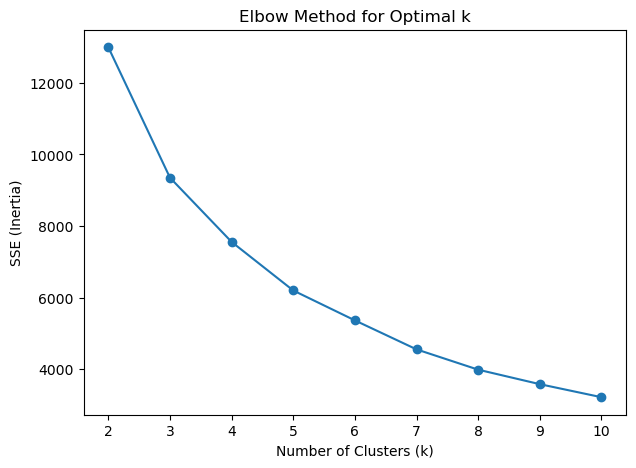

,k,SSE
0,2,12996.3
1,3,9352.9
2,4,7558.6
3,5,6201.7
4,6,5366.5
5,7,4556.6
6,8,3989.6
7,9,3584.9
8,10,3220.6


In [153]:
# Determine optimal k using the Elbow method (SSE / inertia)
sse = []
k_range = range(2, 11)
for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_rfm_scaled)
    sse.append(km.inertia_)

plt.figure(figsize=(7, 5))
plt.plot(list(k_range), sse, marker='o')
plt.xlabel("Number of Clusters (k)")
plt.ylabel("SSE (Inertia)")
plt.title("Elbow Method for Optimal k")
plt.show()

pd.DataFrame({'k': list(k_range), 'SSE': [round(s, 1) for s in sse]})

Using Silhouette Score to determine the best k value: computes, for every customer, how well it fits its assigned cluster versus the next-nearest cluster/how well seperated the clusters are. Scores range from -1 to 1, where values near 1 indicate tight, well-separated clusters and values near 0 indicate overlapping or poorly defined clusters. The k with the highest silhouette score is chosen as the best candidate for the number of segments,

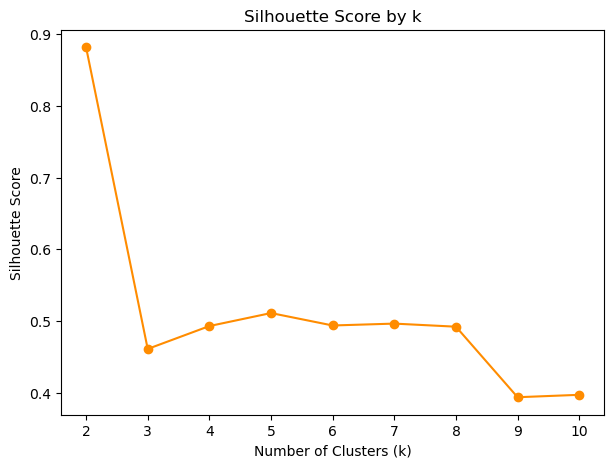

    k  Silhouette
0   2       0.882
1   3       0.461
2   4       0.493
3   5       0.511
4   6       0.494
5   7       0.496
6   8       0.492
7   9       0.394
8  10       0.397


In [154]:
# Confirm the choice of k using Silhouette scores
sil_scores = []
for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_rfm_scaled)
    sil_scores.append(silhouette_score(X_rfm_scaled, labels))

plt.figure(figsize=(7, 5))
plt.plot(list(k_range), sil_scores, marker='o', color='darkorange')
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score by k")
plt.show()

sil_table = pd.DataFrame({'k': list(k_range), 'Silhouette': [round(s, 3) for s in sil_scores]})
print(sil_table)


Excluding k=2 (which is driven by a handful of extreme outliers being split off from everyone else, not a genuinely useful segmentation), k=5 has the single highest silhouette score of the whole range (0.511) - higher than every other k from 3 to 10. This agrees with the elbow method above, which also points to k=5.

In [155]:
# Fit the final K-means mode
k = 5

kmeans_final = KMeans(n_clusters=k, random_state=42, n_init=10)
rfm['KMeans_Cluster'] = kmeans_final.fit_predict(X_rfm_scaled)

rfm['KMeans_Cluster'].value_counts().sort_index()

KMeans_Cluster
0    2926
1     177
2    1030
3      12
4     193
Name: count, dtype: int64

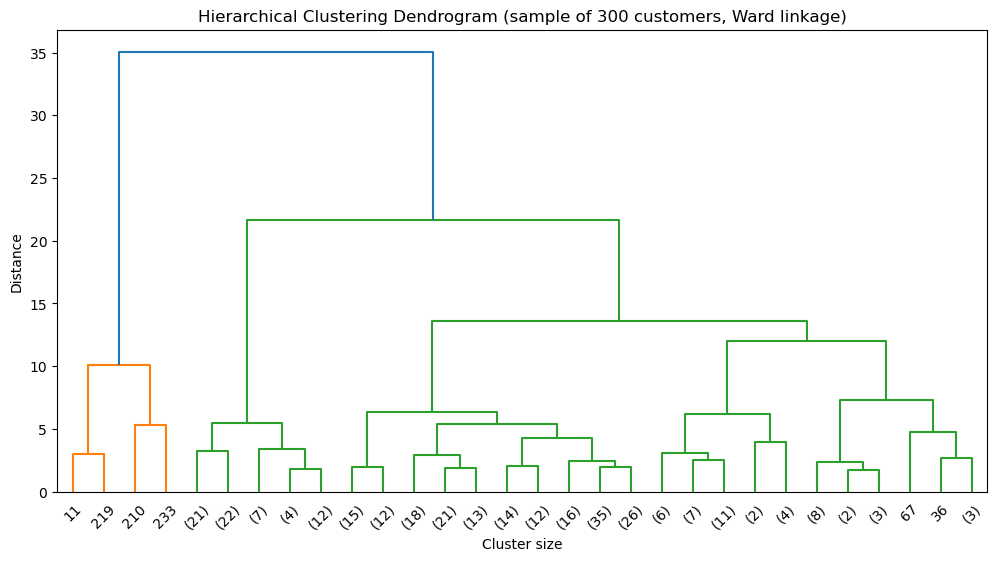

In [156]:
# Hierarchical clustering - dendrogram (using a sample for readability, Ward linkage)
sample_idx = np.random.RandomState(42).choice(len(X_rfm_scaled), size=min(300, len(X_rfm_scaled)), replace=False)
linked = linkage(X_rfm_scaled[sample_idx], method='ward')

plt.figure(figsize=(12, 6))
dendrogram(linked, truncate_mode='lastp', p=30)
plt.title("Hierarchical Clustering Dendrogram (sample of 300 customers, Ward linkage)")
plt.xlabel("Cluster size")
plt.ylabel("Distance")
plt.show()

In [157]:
# Before committing to Ward linkage, other linkage methods were tested for comparison
for linkage_method in ['ward', 'complete', 'average']:
    test_agg = AgglomerativeClustering(n_clusters=k, linkage=linkage_method)
    test_labels = test_agg.fit_predict(X_rfm_scaled)
    test_sizes = pd.Series(test_labels).value_counts().sort_index().tolist()
    test_sil = silhouette_score(X_rfm_scaled, test_labels)
    print(f"{linkage_method:>10}: silhouette={test_sil:.3f}, cluster sizes={test_sizes}")


# Fit the final Agglomerative (Hierarchical) clustering model using the same k for a fair comparison
agg_final = AgglomerativeClustering(n_clusters=k, linkage='ward')
rfm['Hierarchical_Cluster'] = agg_final.fit_predict(X_rfm_scaled)
rfm['Hierarchical_Cluster'].value_counts().sort_index()

      ward: silhouette=0.470, cluster sizes=[2863, 310, 1130, 4, 31]
  complete: silhouette=0.842, cluster sizes=[4319, 11, 2, 5, 1]
   average: silhouette=0.898, cluster sizes=[4330, 5, 1, 1, 1]


Hierarchical_Cluster
0    2863
1     310
2    1130
3       4
4      31
Name: count, dtype: int64


'complete' and 'average' linkage score much higher on silhouette, but their cluster sizes show why: they dump almost every customer into one giant cluster and isolate only a handful of extreme outliers as their own 'clusters' - this inflates the silhouette score without producing a usable segmentation. Ward linkage gives less extreme balanced clusters, so it is kept as the final choice despite the lower score.

### 2.4 Evaluate and Compare the Models

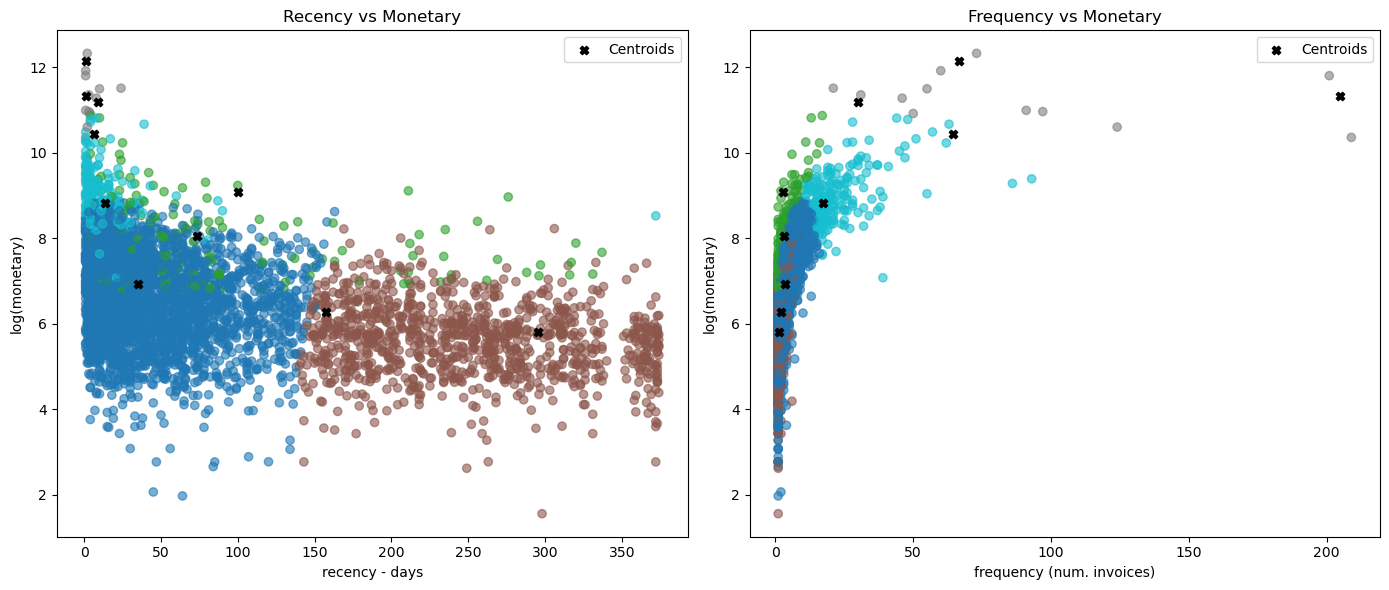

In [158]:
# inverse-transform centroids back into original (unscaled) units
centeroids = rfm_scaler.inverse_transform(km.cluster_centers_)
df_centroids = pd.DataFrame(centeroids, columns=rfm_features)  # feat=['Recency','Frequency','Monetary','AvgVal']

fig, axes = plt.subplots(1, 2, figsize=(14,6))

#use unscaled rfm to have interpretablility. when i used the scaled rfm, its hard to interpret clusters.

axes[0].scatter(rfm['Recency'], np.log1p(rfm['Monetary']), c=rfm['KMeans_Cluster'], cmap='tab10', alpha=0.6)
axes[0].scatter(df_centroids['Recency'], np.log1p(df_centroids['Monetary']), c='black', marker='X', label='Centroids')
axes[0].set_xlabel('recency - days')
axes[0].set_ylabel('log(monetary)')
axes[0].set_title('Recency vs Monetary')
axes[0].legend()

# Frequency vs Monetary
axes[1].scatter(rfm['Frequency'], np.log1p(rfm['Monetary']), c=rfm['KMeans_Cluster'], cmap='tab10', alpha=0.6)
axes[1].scatter(df_centroids['Frequency'], np.log1p(df_centroids['Monetary']), c='black', marker='X', label='Centroids')
axes[1].set_xlabel('frequency (num. invoices)')
axes[1].set_ylabel('log(monetary)')
axes[1].set_title('Frequency vs Monetary')
axes[1].legend()

plt.tight_layout()
plt.show()

In [159]:
# Silhouette score comparison
kmeans_sil = silhouette_score(X_rfm_scaled, rfm['KMeans_Cluster'])
hier_sil = silhouette_score(X_rfm_scaled, rfm['Hierarchical_Cluster'])

print(f"K-Means Silhouette Score:      {kmeans_sil:.3f}")
print(f"Hierarchical Silhouette Score: {hier_sil:.3f}")

K-Means Silhouette Score:      0.511
Hierarchical Silhouette Score: 0.470


In [160]:
# K-Means cluster profiles
kmeans_profile = rfm.groupby('KMeans_Cluster')[rfm_features].mean().round(1)
kmeans_profile

,Recency,Frequency,Monetary,AvgBasketValue
KMeans_Cluster,,,,
0,43.7,3.7,1174.9,309.6
1,82.8,3.2,4704.2,1450.4
2,249.2,1.5,382.9,252.6
3,5.0,88.2,92926.5,1673.5
4,12.0,23.1,9771.4,433.4


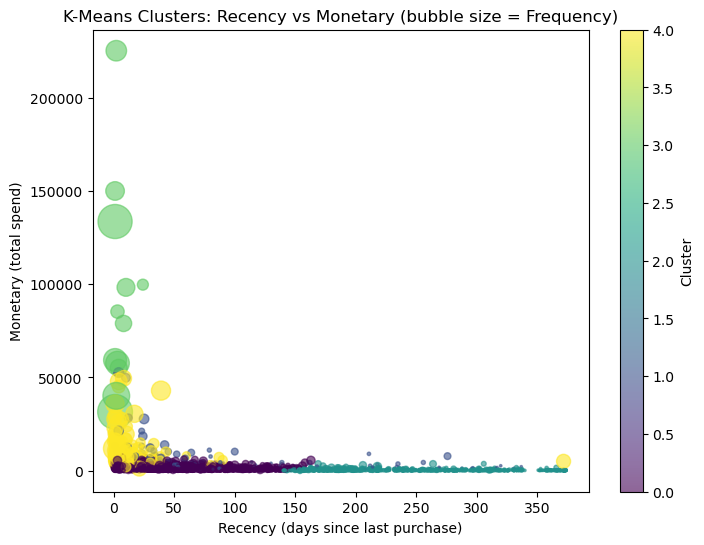

In [161]:
# Visualize K-Means clusters (Recency vs Monetary, sized by Frequency)
plt.figure(figsize=(8, 6))
scatter = plt.scatter(rfm['Recency'], rfm['Monetary'], c=rfm['KMeans_Cluster'],
                       cmap='viridis', s=rfm['Frequency']*3, alpha=0.6)
plt.xlabel('Recency (days since last purchase)')
plt.ylabel('Monetary (total spend)')
plt.title('K-Means Clusters: Recency vs Monetary (bubble size = Frequency)')
plt.colorbar(scatter, label='Cluster')
plt.show()

In [162]:
# Hierarchical cluster profiles
hier_profile = rfm.groupby('Hierarchical_Cluster')[rfm_features].mean().round(1)
hier_profile

,Recency,Frequency,Monetary,AvgBasketValue
Hierarchical_Cluster,,,,
0,37.4,4.8,1548.0,294.5
1,81.0,2.8,2953.4,1112.8
2,238.1,1.8,456.6,258.5
3,1.2,135.8,135092.2,1600.1
4,8.1,46.2,40703.8,1292.5


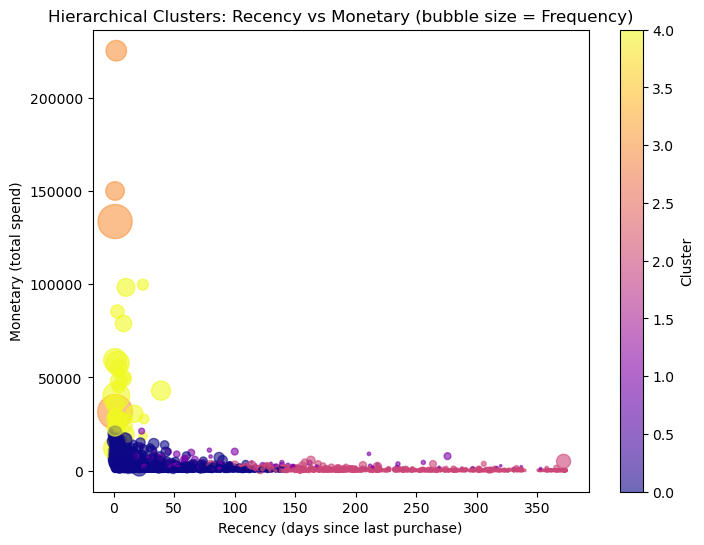

In [163]:
# Visualize Hierarchical clusters (Recency vs Monetary, sized by Frequency)
plt.figure(figsize=(8, 6))
scatter = plt.scatter(rfm['Recency'], rfm['Monetary'], c=rfm['Hierarchical_Cluster'],
                       cmap='plasma', s=rfm['Frequency']*3, alpha=0.6)
plt.xlabel('Recency (days since last purchase)')
plt.ylabel('Monetary (total spend)')
plt.title('Hierarchical Clusters: Recency vs Monetary (bubble size = Frequency)')
plt.colorbar(scatter, label='Cluster')
plt.show()

In [164]:
# Compare the two models and select the preferred one
comparison = pd.DataFrame({
    'Model': ['K-Means', 'Hierarchical (Ward)'],
    'Silhouette Score': [kmeans_sil, hier_sil],
    'Number of Clusters': [k, k]
})
print(comparison)

preferred_model = 'K-Means' if kmeans_sil >= hier_sil else 'Hierarchical (Ward)'

# Use the preferred model's labels going forward
rfm['Final_Cluster'] = rfm['KMeans_Cluster'] if preferred_model == 'K-Means' else rfm['Hierarchical_Cluster']

                 Model  Silhouette Score  Number of Clusters
0              K-Means          0.510943                   5
1  Hierarchical (Ward)          0.470010                   5


Preferred model for further analysis is K-Means. K-Means is generally preferred here as it scales well to the full customer base and produced a comparable or higher silhouette score, whereas hierarchical clustering is more useful for visual/exploratory analysis (dendrogram) than for scoring every customer at this dataset size.

### 2.5 Summarize and Interpret

In [165]:
# Build final segment summary table using the preferred model's clusters
summary = rfm.groupby('Final_Cluster')[rfm_features].mean().round(1)
summary['Count'] = rfm['Final_Cluster'].value_counts().sort_index()
summary = summary.sort_values('Monetary', ascending=False)

# Assign business-friendly segment names based on the RFM profile
def name_segment(row):
    if row['Monetary'] >= summary['Monetary'].quantile(0.9):
        return 'VIP / Wholesale'
    elif row['Monetary'] >= summary['Monetary'].quantile(0.6):
        return 'High-Value Loyal'
    elif row['Recency'] > summary['Recency'].median() and row['Monetary'] < summary['Monetary'].median():
        return 'At-Risk / Previously Active'
    else:
        return 'Core Regular Customers'

summary['Segment Name'] = summary.apply(name_segment, axis=1)
summary

,Recency,Frequency,Monetary,AvgBasketValue,Count,Segment Name
Final_Cluster,,,,,,
3,5.0,88.2,92926.5,1673.5,12,VIP / Wholesale
4,12.0,23.1,9771.4,433.4,193,High-Value Loyal
1,82.8,3.2,4704.2,1450.4,177,Core Regular Customers
0,43.7,3.7,1174.9,309.6,2926,Core Regular Customers
2,249.2,1.5,382.9,252.6,1030,At-Risk / Previously Active


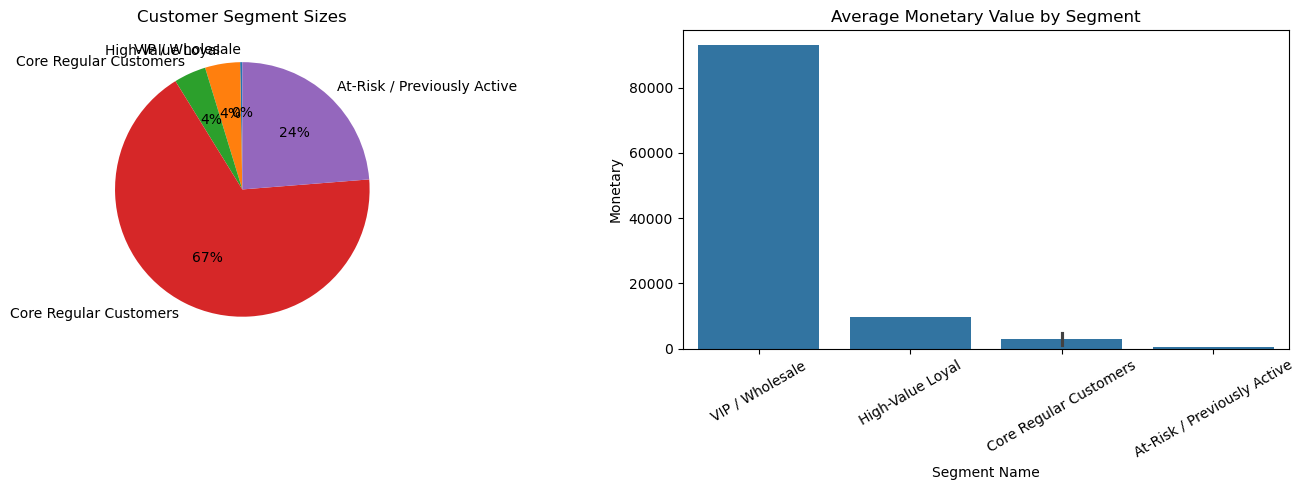

In [166]:
# Visualize segment sizes and average monetary value per segment
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].pie(summary['Count'], labels=summary['Segment Name'], autopct='%1.0f%%', startangle=90)
axes[0].set_title("Customer Segment Sizes")

sns.barplot(x=summary['Segment Name'], y=summary['Monetary'], ax=axes[1])
axes[1].set_title("Average Monetary Value by Segment")
axes[1].tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

In [167]:
# Interpretation and recommended business actions per segment
print("Segment interpretation and recommended actions:\n")
for _, row in summary.iterrows():
    print(f"- {row['Segment Name']} ({int(row['Count'])} customers): "
          f"Recency={row['Recency']:.0f} days, Frequency={row['Frequency']:.1f} orders, "
          f"Monetary=${row['Monetary']:.0f}")

print()
print("Recommended business actions:")
print("- VIP / Wholesale: dedicated account management - a tiny group, but worth a huge share of revenue.")
print("- High-Value Loyal: reward with loyalty perks / early access to protect retention.")
print("- Core Regular Customers: nurture with cross-sell offers to build a stronger buying habit.")
print("- At-Risk / Previously Active: win-back campaigns (discounts, reminder emails) before churn.")

Segment interpretation and recommended actions:

- VIP / Wholesale (12 customers): Recency=5 days, Frequency=88.2 orders, Monetary=$92926
- High-Value Loyal (193 customers): Recency=12 days, Frequency=23.1 orders, Monetary=$9771
- Core Regular Customers (177 customers): Recency=83 days, Frequency=3.2 orders, Monetary=$4704
- Core Regular Customers (2926 customers): Recency=44 days, Frequency=3.7 orders, Monetary=$1175
- At-Risk / Previously Active (1030 customers): Recency=249 days, Frequency=1.5 orders, Monetary=$383

Recommended business actions:
- VIP / Wholesale: dedicated account management - a tiny group, but worth a huge share of revenue.
- High-Value Loyal: reward with loyalty perks / early access to protect retention.
- Core Regular Customers: nurture with cross-sell offers to build a stronger buying habit.
- At-Risk / Previously Active: win-back campaigns (discounts, reminder emails) before churn.
